# Reweighing (Kamiran & Calders, 2012) on German Credit, COMPAS and Adult

**Paper:** F. Kamiran and T. Calders, *Data preprocessing techniques for classification without discrimination*, Knowledge and Information Systems 33 (2012).

**Algorithm:** Reweighing, a **pre-processing** method. Labels and features are left unchanged; every training example gets a weight that depends only on its group $S$ and its label $Y$:

$$W(s, c) = \frac{P(S=s)\,P(Y=c)}{P(S=s,\,Y=c)}$$

Group–label combinations that are rarer than independence would predict (unprivileged with the favourable label, privileged with the unfavourable label) get $W>1$; over-represented combinations get $W<1$. In the weighted training data $Y$ is independent of $S$ (DP_Diff = 0) and the overall rate of favourable labels is unchanged. Any classifier that accepts sample weights is then trained on the weighted data (paper, Algorithm 3, p. 16–17).
Implementation: `aif360.algorithms.preprocessing.Reweighing` (checked against the formula above in Step 4).

**Metrics** (favourable label $=1$, U = unprivileged group $S=0$, P = privileged group $S=1$):

| Metric | Formula | Ideal |
|---|---|---|
| DP_Diff | $P(\hat Y=1 \mid U) - P(\hat Y=1 \mid P)$ | 0 (negative = U disadvantaged) |
| DIR | $P(\hat Y=1 \mid U)\,/\,P(\hat Y=1 \mid P)$ | 1 (below 0.8 violates the four-fifths rule) |
| Consistency | $1 - \frac{1}{n}\sum_i \bigl\lvert \hat y_i - \frac{1}{k}\sum_{j \in kNN(x_i)} \hat y_j \bigr\rvert$ | 1 |

Step 2 computes the metrics on the original labels $Y$ of the whole dataset. In the before-vs-after comparison (Step 6), *before* = the original labels of the held-out test set and *after* = the predictions for the same test rows.

**Parameter settings**

| Setting | Value |
|---|---|
| Train/test split | 70 % / 30 %, stratified on the 4 cells (group × label), `random_state = 42` |
| Reweighing | no hyper-parameters; weights are computed from the training split only |
| Classifier | `StandardScaler` + `LogisticRegression(max_iter=5000)` (L2, C = 1, lbfgs), decision threshold 0.5 |
| Use of $S$ | $S$ is used to compute the weights and the metrics, but is **not** an input of the classifier (paper p. 14) |
| Consistency | k = 5 nearest neighbours (AIF360 default), Euclidean distance on min-max-scaled one-hot features (without $S$) |
| Baseline | the same classifier trained without weights, to separate the effect of Reweighing from the effect of the model |
| Robustness | the whole pipeline is repeated for 10 random splits (seeds 42–51) |

## Setup

In [63]:
import logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# AIF360 logs a note for every optional package that is not installed (fairlearn, inFairness, ...).
# Only these import-time notes are silenced; Python warnings (e.g. convergence warnings) stay visible.
_root_logger = logging.getLogger()
_previous_level = _root_logger.level
_root_logger.setLevel(logging.ERROR)
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.algorithms.preprocessing import Reweighing
from aif360.sklearn.metrics import consistency_score
_root_logger.setLevel(_previous_level)

SEED, TEST_SIZE, K = 42, 0.30, 5
ROBUSTNESS_SEEDS = range(42, 52)
PRIV, UNPRIV = [{"S": 1}], [{"S": 0}]      # S = 1 privileged, S = 0 unprivileged

DATA_DIR = Path.cwd()                        # folder that holds adult/, compas/ and german/
assert (DATA_DIR / "adult").exists(), "Open the notebook from the folder that contains the dataset folders"
RESULTS_DIR, FIG_DIR = DATA_DIR / "results", DATA_DIR / "figures"
RESULTS_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

## Step 1 – The three datasets

| Dataset | File | Protected attribute $S$ (1 = privileged) | Favourable label ($Y=1$) |
|---|---|---|---|
| German Credit | `german/german.data` (UCI) | age > 25 | good credit risk |
| COMPAS | `compas/compas-scores-two-years.csv` (ProPublica) | race = Caucasian (vs. all other races) | no recidivism within two years |
| Adult | `adult/adult.csv` (UCI census income) | sex = Male | income > 50K |

Cleaning:
* **German** – the 20 UCI attributes are named; `personal_status` is replaced by `sex` (it mixes sex and marital status); `age` is removed from the inputs because $S$ is derived from it.
* **COMPAS** – ProPublica's standard filters (`days_b_screening_arrest` in [−30, 30], `is_recid ≠ −1`, `c_charge_degree ≠ 'O'`, score present); 5 rows without a charge description are dropped (6,167 rows, as in AIF360). The COMPAS score itself is **not** used as a feature; `race` is removed from the inputs.
* **Adult** – rows with missing values (`?`) removed (30,162 rows); `fnlwgt` and `education` (duplicate of `education.num`) dropped; `sex` is removed from the inputs.

All categorical columns are one-hot encoded.

In [64]:
GERMAN_COLS = ["checking_status", "duration", "credit_history", "purpose", "credit_amount",
               "savings", "employment_since", "installment_rate", "personal_status", "other_debtors",
               "residence_since", "property", "age", "other_installment_plans", "housing",
               "existing_credits", "job", "num_dependents", "telephone", "foreign_worker", "credit_risk"]

def load_german():
    df = pd.read_csv(DATA_DIR / "german" / "german.data", sep=r"\s+", header=None, names=GERMAN_COLS)
    df["sex"] = df["personal_status"].map({"A91": "male", "A93": "male", "A94": "male",
                                           "A92": "female", "A95": "female"})
    s = (df["age"] > 25).astype(int)                 # 1 = privileged: older than 25
    y = (df["credit_risk"] == 1).astype(int)         # 1 = favourable: good credit risk
    X = df.drop(columns=["credit_risk", "age", "personal_status"])
    return X, y, s

def load_compas():
    df = pd.read_csv(DATA_DIR / "compas" / "compas-scores-two-years.csv")
    df = df[df["days_b_screening_arrest"].between(-30, 30) & (df["is_recid"] != -1)
            & (df["c_charge_degree"] != "O") & df["score_text"].notna()]
    feats = ["sex", "age", "age_cat", "juv_fel_count", "juv_misd_count", "juv_other_count",
             "priors_count", "c_charge_degree", "c_charge_desc"]
    df = df.dropna(subset=feats).reset_index(drop=True)
    s = (df["race"] == "Caucasian").astype(int)      # 1 = privileged: Caucasian
    y = (df["two_year_recid"] == 0).astype(int)      # 1 = favourable: did not reoffend
    return df[feats], y, s

def load_adult():
    df = pd.read_csv(DATA_DIR / "adult" / "adult.csv", na_values="?").dropna().reset_index(drop=True)
    s = (df["sex"] == "Male").astype(int)            # 1 = privileged: male
    y = (df["income"] == ">50K").astype(int)         # 1 = favourable: income > 50K
    X = df.drop(columns=["income", "sex", "fnlwgt", "education"])
    return X, y, s

DATASETS = {
    "German": dict(load=load_german, S="age",  priv="age > 25",  unpriv="age ≤ 25",      fav="good credit risk"),
    "COMPAS": dict(load=load_compas, S="race", priv="Caucasian", unpriv="non-Caucasian", fav="no recidivism (2 yrs)"),
    "Adult":  dict(load=load_adult,  S="sex",  priv="male",      unpriv="female",        fav="income > 50K"),
}

data = {}
for name, cfg in DATASETS.items():
    X, y, s = cfg["load"]()
    X = pd.get_dummies(X, dtype=float)                       # one-hot encoding; S is not in X
    data[name] = dict(X=X, y=y.to_numpy(), s=s.to_numpy(),
                      X_mm=MinMaxScaler().fit_transform(X))  # [0, 1] features = distance space for consistency

pd.DataFrame({name: {"Rows": len(d["y"]), "Features (one-hot)": d["X"].shape[1],
                     "S": DATASETS[name]["S"], "Privileged (S=1)": DATASETS[name]["priv"],
                     "Share privileged": round(d["s"].mean(), 3),
                     "Favourable (Y=1)": DATASETS[name]["fav"], "Share favourable": round(d["y"].mean(), 3)}
              for name, d in data.items()}).T

,Rows,Features (one-hot),S,Privileged (S=1),Share privileged,Favourable (Y=1),Share favourable
German,1000,58,age,age > 25,0.81,good credit risk,0.7
COMPAS,6167,401,race,Caucasian,0.341,no recidivism (2 yrs),0.545
Adult,30162,85,sex,male,0.676,income > 50K,0.249


## Step 2 – Fairness of the original labels (before any mitigation or training)

In [65]:
def to_bld(y, s, w=None):
    """Wrap labels and protected attribute in an AIF360 BinaryLabelDataset."""
    ds = BinaryLabelDataset(df=pd.DataFrame({"S": np.asarray(s), "y": np.asarray(y)}),
                            label_names=["y"], protected_attribute_names=["S"],
                            favorable_label=1, unfavorable_label=0)
    if w is not None:
        ds.instance_weights = np.asarray(w, dtype=float)
    return ds

def fairness_metrics(y, s, X_mm, w=None):
    """Group rates, DP_Diff and DIR (AIF360) and consistency (AIF360, k = 5) of a label vector."""
    m = BinaryLabelDatasetMetric(to_bld(y, s, w), unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    out = {"P(+|U)": m.base_rate(privileged=False), "P(+|P)": m.base_rate(privileged=True),
           "DP_Diff": m.statistical_parity_difference(), "DIR": m.disparate_impact()}
    if X_mm is not None:
        out["Consistency"] = consistency_score(X_mm, np.asarray(y), n_neighbors=K)
    return out

before = pd.DataFrame({name: fairness_metrics(d["y"], d["s"], d["X_mm"]) for name, d in data.items()}).T
before.assign(**{"Passes four-fifths rule (DIR ≥ 0.8)": before["DIR"] >= 0.8})

,P(+|U),P(+|P),DP_Diff,DIR,Consistency,Passes four-fifths rule (DIR ≥ 0.8)
German,0.579,0.728,-0.149,0.795,0.741,False
COMPAS,0.511,0.609,-0.097,0.840,0.669,True
Adult,0.114,0.314,-0.200,0.362,0.830,False


On the original labels the favourable outcome is rarer for the unprivileged group in every dataset (DP_Diff < 0). The last column shows which datasets fail the four-fifths rule (DIR < 0.8).

## Step 3 – Stratified train/test split

The split is stratified on the four group × label cells, so that both parts keep the same group sizes and the same label bias as the full data.

In [66]:
def split(d, seed):
    strata = 2 * d["s"] + d["y"]                     # 4 cells: (S, Y)
    return train_test_split(np.arange(len(d["y"])), test_size=TEST_SIZE,
                            stratify=strata, random_state=seed)

for name, d in data.items():
    d["tr"], d["te"] = split(d, SEED)

pd.DataFrame({name: {"n train": len(d["tr"]), "n test": len(d["te"]),
                     "DP_Diff train labels": fairness_metrics(d["y"][d["tr"]], d["s"][d["tr"]], None)["DP_Diff"],
                     "DP_Diff test labels":  fairness_metrics(d["y"][d["te"]], d["s"][d["te"]], None)["DP_Diff"]}
              for name, d in data.items()}).T

,n train,n test,DP_Diff train labels,DP_Diff test labels
German,700.0,300.0,-0.149,-0.149
COMPAS,4316.0,1851.0,-0.097,-0.097
Adult,21113.0,9049.0,-0.200,-0.200


## Step 4 – Mitigation: Reweighing the training data, then training the classifier

Reweighing is a pre-processing method, so it is fitted **only on the training split**. The test split is never reweighed.

In [67]:
def reweigh(y, s):
    """AIF360 Reweighing: returns one weight per training example and the fitted transformer."""
    rw = Reweighing(unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    weighted = rw.fit_transform(to_bld(y, s))
    return weighted.instance_weights, rw

def paper_weight(y, s, s_val, y_val):
    """Kamiran & Calders, Algorithm 3: W = P(S=s) P(Y=c) / P(S=s, Y=c)."""
    return (s == s_val).mean() * (y == y_val).mean() / ((s == s_val) & (y == y_val)).mean()

weights_table, train_check = {}, {}
for name, d in data.items():
    y_tr, s_tr = d["y"][d["tr"]], d["s"][d["tr"]]
    d["w"], rw = reweigh(y_tr, s_tr)
    aif = {"W(U,+)": rw.w_up_fav, "W(U,-)": rw.w_up_unfav, "W(P,+)": rw.w_p_fav, "W(P,-)": rw.w_p_unfav}
    own = [paper_weight(y_tr, s_tr, 0, 1), paper_weight(y_tr, s_tr, 0, 0),
           paper_weight(y_tr, s_tr, 1, 1), paper_weight(y_tr, s_tr, 1, 0)]
    assert np.allclose(list(aif.values()), own), "AIF360 weights differ from the paper's formula"
    weights_table[name] = aif
    train_check[name] = {
        "DP_Diff train (unweighted)": fairness_metrics(y_tr, s_tr, None)["DP_Diff"],
        "DP_Diff train (reweighed)":  fairness_metrics(y_tr, s_tr, None, w=d["w"])["DP_Diff"],
        "P(+) train (unweighted)": y_tr.mean(),
        "P(+) train (reweighed)":  np.average(y_tr, weights=d["w"]),
    }

print("Weights per group-label cell (identical to the paper's formula):")
display(pd.DataFrame(weights_table).T)
print("Effect of the weights on the training labels:")
display(pd.DataFrame(train_check).T.round(4))

Weights per group-label cell (identical to the paper's formula):


,"W(U,+)","W(U,-)","W(P,+)","W(P,-)"
German,1.209,0.713,0.961,1.105
COMPAS,1.065,0.932,0.895,1.164
Adult,2.191,0.847,0.793,1.095


Effect of the weights on the training labels:


,DP_Diff train (unweighted),DP_Diff train (reweighed),P(+) train (unweighted),P(+) train (reweighed)
German,-0.149,-0.0,0.700,0.700
COMPAS,-0.097,0.0,0.544,0.544
Adult,-0.200,-0.0,0.249,0.249


As the paper promises, the weighted training data have DP_Diff = 0 and the same overall rate of favourable labels. The weights are largest for unprivileged people with the favourable label and privileged people with the unfavourable label.

Next, the same classifier is trained twice on the same training split: once **without weights** (baseline) and once **with the Reweighing weights** (mitigated). $S$ is not one of the inputs.

In [68]:
def fit_lr(X, y, w=None):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    return clf.fit(X, y, logisticregression__sample_weight=w)

for name, d in data.items():
    X_tr, y_tr = d["X"].iloc[d["tr"]], d["y"][d["tr"]]
    d["baseline"] = fit_lr(X_tr, y_tr)
    d["reweighed"] = fit_lr(X_tr, y_tr, d["w"])
print("Classifiers trained:", list(data))

Classifiers trained: ['German', 'COMPAS', 'Adult']


## Step 5 – Evaluation on the held-out test data

In [69]:
def evaluate(y_true, y_pred, s, X_mm):
    out = fairness_metrics(y_pred, s, X_mm)
    out.update({"Accuracy": accuracy_score(y_true, y_pred),
                "Balanced acc.": balanced_accuracy_score(y_true, y_pred),
                "F1": f1_score(y_true, y_pred)})
    return out

rows = []
for name, d in data.items():
    te, X_te, y_te, s_te, Xmm_te = d["te"], d["X"].iloc[d["te"]], d["y"][d["te"]], d["s"][d["te"]], d["X_mm"][d["te"]]
    rows.append({"Dataset": name, "Setting": "Original labels (test)", **fairness_metrics(y_te, s_te, Xmm_te)})
    for setting, model in [("Baseline LR (test)", d["baseline"]), ("Reweighing + LR (test)", d["reweighed"])]:
        y_hat = model.predict(X_te)
        d["pred_" + setting.split()[0].lower()] = y_hat
        rows.append({"Dataset": name, "Setting": setting, **evaluate(y_te, y_hat, s_te, Xmm_te)})

test_results = pd.DataFrame(rows).set_index(["Dataset", "Setting"])
test_results

P(+|U)  P(+|P)  DP_Diff    DIR  Consistency  \
Dataset Setting                                                               
German  Original labels (test)   0.579   0.728   -0.149  0.795        0.731   
        Baseline LR (test)       0.737   0.848   -0.111  0.869        0.843   
        Reweighing + LR (test)   0.737   0.844   -0.107  0.873        0.837   
COMPAS  Original labels (test)   0.511   0.609   -0.097  0.840        0.663   
        Baseline LR (test)       0.548   0.707   -0.159  0.775        0.862   
        Reweighing + LR (test)   0.558   0.702   -0.144  0.795        0.864   
Adult   Original labels (test)   0.114   0.314   -0.200  0.363        0.826   
        Baseline LR (test)       0.080   0.274   -0.193  0.294        0.943   
        Reweighing + LR (test)   0.129   0.231   -0.102  0.558        0.945   

                                Accuracy  Balanced acc.     F1  
Dataset Setting                                                 
German  Original labels (test)       NaN            NaN    NaN  
        Baseline LR (test)         0.767          0.662  0.847  
        Reweighing + LR (test)     0.783          0.683  0.858  
COMPAS  Original labels (test)       NaN            NaN    NaN  
        Baseline LR (test)         0.665          0.657  0.708  
        Reweighing + LR (test)     0.667          0.659  0.711  
Adult   Original labels (test)       NaN            NaN    NaN  
        Baseline LR (test)         0.846          0.768  0.664  
        Reweighing + LR (test)     0.843          0.756  0.649

## Step 6 – Before vs. after mitigation

"Before" = original labels of the test split (the same rows as the predictions; Step 2 shows that the full data give the same DP_Diff).

In [70]:
METRICS = ["DP_Diff", "DIR", "Consistency"]
BEFORE = "Original labels (test)"
comparison = []
for name in data:
    b = test_results.loc[(name, BEFORE), METRICS]
    base = test_results.loc[(name, "Baseline LR (test)"), METRICS]
    after = test_results.loc[(name, "Reweighing + LR (test)"), METRICS]
    for m in METRICS:
        comparison.append({"Dataset": name, "Metric": m, "Before (original labels)": b[m],
                           "Baseline LR (test)": base[m], "After (Reweighing + LR, test)": after[m],
                           "Change after − before": after[m] - b[m]})
comparison = pd.DataFrame(comparison).set_index(["Dataset", "Metric"])

before.to_csv(RESULTS_DIR / "before_original_labels.csv")
test_results.to_csv(RESULTS_DIR / "test_results_seed42.csv")
comparison.to_csv(RESULTS_DIR / "before_vs_after.csv")
pd.DataFrame(weights_table).T.to_csv(RESULTS_DIR / "reweighing_weights.csv")
comparison

Before (original labels)  Baseline LR (test)  \
Dataset Metric                                                      
German  DP_Diff                        -0.149              -0.111   
        DIR                             0.795               0.869   
        Consistency                     0.731               0.843   
COMPAS  DP_Diff                        -0.097              -0.159   
        DIR                             0.840               0.775   
        Consistency                     0.663               0.862   
Adult   DP_Diff                        -0.200              -0.193   
        DIR                             0.363               0.294   
        Consistency                     0.826               0.943   

                     After (Reweighing + LR, test)  Change after − before  
Dataset Metric                                                             
German  DP_Diff                             -0.107                  0.043  
        DIR                                  0.873                  0.079  
        Consistency                          0.837                  0.106  
COMPAS  DP_Diff                             -0.144                 -0.047  
        DIR                                  0.795                 -0.045  
        Consistency                          0.864                  0.201  
Adult   DP_Diff                             -0.102                  0.098  
        DIR                                  0.558                  0.196  
        Consistency                          0.945                  0.119

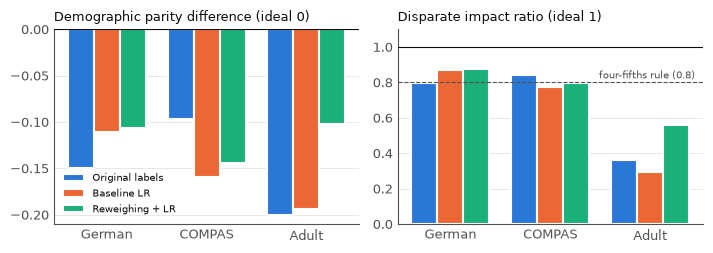

In [71]:
# Light-mode categorical slots 1-3 of the reference palette; text stays in neutral ink.
COLORS = {"Original labels": "#2a78d6", "Baseline LR": "#eb6834", "Reweighing + LR": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})

values = {
    "Original labels": test_results.xs(BEFORE, level="Setting")[["DP_Diff", "DIR"]],
    "Baseline LR": test_results.xs("Baseline LR (test)", level="Setting")[["DP_Diff", "DIR"]],
    "Reweighing + LR": test_results.xs("Reweighing + LR (test)", level="Setting")[["DP_Diff", "DIR"]],
}
names, x, width = list(data), np.arange(len(data)), 0.26

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
for ax, metric, ideal, title in [(axes[0], "DP_Diff", 0.0, "Demographic parity difference (ideal 0)"),
                                 (axes[1], "DIR", 1.0, "Disparate impact ratio (ideal 1)")]:
    for i, (label, df) in enumerate(values.items()):
        ax.bar(x + (i - 1) * width, df.loc[names, metric], width, label=label,
               color=COLORS[label], edgecolor="white", linewidth=1.5, zorder=3)
    ax.axhline(ideal, color=INK, linewidth=0.8, zorder=4)
    if metric == "DIR":
        ax.axhline(0.8, color=MUTED, linewidth=0.8, linestyle="--", zorder=4)
        ax.text(len(names) - 0.55, 0.81, "four-fifths rule (0.8)", ha="right", va="bottom", fontsize=7, color=MUTED)
        ax.set_ylim(0, 1.1)
    ax.set_xticks(x, names)
    ax.set_title(title, fontsize=9, loc="left")
    ax.grid(axis="y", color=GRID, linewidth=0.6, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(length=0)
axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fairness_before_after.png", dpi=220, bbox_inches="tight")
plt.show()

## Robustness – 10 random stratified splits

German has only 300 test rows, so a single split can be noisy. The complete pipeline (split → Reweighing on the training part → LR → test metrics) is repeated for seeds 42–51; mean ± standard deviation is reported.

In [72]:
runs = []
for name, d in data.items():
    for seed in ROBUSTNESS_SEEDS:
        tr, te = split(d, seed)
        X_tr, y_tr, s_tr = d["X"].iloc[tr], d["y"][tr], d["s"][tr]
        X_te, y_te, s_te, Xmm_te = d["X"].iloc[te], d["y"][te], d["s"][te], d["X_mm"][te]
        w, _ = reweigh(y_tr, s_tr)
        for setting, model in [("Baseline LR", fit_lr(X_tr, y_tr)), ("Reweighing + LR", fit_lr(X_tr, y_tr, w))]:
            runs.append({"Dataset": name, "Setting": setting, "Seed": seed,
                         **evaluate(y_te, model.predict(X_te), s_te, Xmm_te)})
runs = pd.DataFrame(runs)
runs.to_csv(RESULTS_DIR / "robustness_10_splits.csv", index=False)

cols = ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc.", "F1"]
agg = runs.groupby(["Dataset", "Setting"], sort=False)[cols].agg(["mean", "std"])
summary = pd.DataFrame({c: agg[(c, "mean")].map("{:.3f}".format) + " ± " + agg[(c, "std")].map("{:.3f}".format)
                        for c in cols})
summary.to_csv(RESULTS_DIR / "robustness_summary.csv")
display(summary)

# Paired view: same split, with vs. without weights
paired = runs.pivot_table(index=["Dataset", "Seed"], columns="Setting", values=["DP_Diff", "Accuracy"])
gain = pd.DataFrame({
    "DP_Diff gap closed (mean)": (paired[("DP_Diff", "Reweighing + LR")] - paired[("DP_Diff", "Baseline LR")]).groupby(level=0).mean(),
    "Splits where |DP_Diff| fell": (paired[("DP_Diff", "Reweighing + LR")].abs() < paired[("DP_Diff", "Baseline LR")].abs()).groupby(level=0).sum(),
    "Accuracy change (mean)": (paired[("Accuracy", "Reweighing + LR")] - paired[("Accuracy", "Baseline LR")]).groupby(level=0).mean(),
}).loc[list(data)]
gain

DP_Diff            DIR    Consistency  \
Dataset Setting                                                         
German  Baseline LR      -0.124 ± 0.058  0.847 ± 0.069  0.832 ± 0.015   
        Reweighing + LR  -0.090 ± 0.066  0.890 ± 0.079  0.833 ± 0.015   
COMPAS  Baseline LR      -0.159 ± 0.023  0.778 ± 0.030  0.873 ± 0.006   
        Reweighing + LR  -0.150 ± 0.024  0.790 ± 0.031  0.873 ± 0.006   
Adult   Baseline LR      -0.185 ± 0.006  0.308 ± 0.023  0.942 ± 0.003   
        Reweighing + LR  -0.098 ± 0.005  0.566 ± 0.022  0.943 ± 0.002   

                              Accuracy  Balanced acc.             F1  
Dataset Setting                                                       
German  Baseline LR      0.752 ± 0.015  0.665 ± 0.022  0.832 ± 0.012  
        Reweighing + LR  0.750 ± 0.022  0.660 ± 0.027  0.832 ± 0.016  
COMPAS  Baseline LR      0.667 ± 0.008  0.659 ± 0.008  0.712 ± 0.008  
        Reweighing + LR  0.665 ± 0.008  0.656 ± 0.009  0.711 ± 0.008  
Adult   Baseline LR      0.847 ± 0.003  0.768 ± 0.006  0.665 ± 0.008  
        Reweighing + LR  0.842 ± 0.004  0.753 ± 0.006  0.644 ± 0.010

,DP_Diff gap closed (mean),Splits where |DP_Diff| fell,Accuracy change (mean)
Dataset,,,
German,0.035,9,-0.002
COMPAS,0.008,9,-0.002
Adult,0.087,10,-0.005


## Sensitivity check – what if $S$ were a model input?

This is the paper's reference **setting 2** (p. 22, Fig. 7): $S$ is used both for training and at prediction time. The authors add it only for comparison, because it breaks their assumption A2 that $S$ must not be used for predictions. The main pipeline above follows the spirit of their **setting 1**, where $S$ is not used for prediction. One difference: here $S$ is also left out of the training features, while the paper keeps it in the training set.

This check is not the proposed method. It is used only to explain why Reweighing has a weaker effect when the classifier cannot see $S$. The same 10 splits (seeds 42–51) are used, with $S$ added as one extra input column.

In [73]:
abl = []
for name, d in data.items():
    X_s = d["X"].assign(S=d["s"])
    for seed in ROBUSTNESS_SEEDS:
        tr, te = split(d, seed)
        w, _ = reweigh(d["y"][tr], d["s"][tr])
        for setting, ww in [("Baseline LR + S", None), ("Reweighing + LR + S", w)]:
            y_hat = fit_lr(X_s.iloc[tr], d["y"][tr], ww).predict(X_s.iloc[te])
            abl.append({"Dataset": name, "Setting": setting, "Seed": seed,
                        **fairness_metrics(y_hat, d["s"][te], None),
                        "Accuracy": accuracy_score(d["y"][te], y_hat)})
abl = pd.DataFrame(abl)
abl.to_csv(RESULTS_DIR / "sensitivity_S_as_input.csv", index=False)
abl.groupby(["Dataset", "Setting"], sort=False)[["DP_Diff", "DIR", "Accuracy"]].mean()

DP_Diff    DIR  Accuracy
Dataset Setting                                      
German  Baseline LR + S       -0.193  0.766     0.751
        Reweighing + LR + S   -0.034  0.960     0.747
COMPAS  Baseline LR + S       -0.166  0.769     0.668
        Reweighing + LR + S   -0.020  0.970     0.664
Adult   Baseline LR + S       -0.192  0.290     0.848
        Reweighing + LR + S   -0.093  0.584     0.842

## Summary

Both tables are computed from the results above; nothing is typed by hand.

In [74]:
def arrow(values):
    """Format a sequence of metric values as 'a → b → c'."""
    return " → ".join(f"{v:.3f}".replace("-", "−") for v in values)

BASE, AFTER = "Baseline LR (test)", "Reweighing + LR (test)"
summary_table = {}
for name in data:
    b, base, after = test_results.loc[(name, BEFORE)], test_results.loc[(name, BASE)], test_results.loc[(name, AFTER)]
    summary_table[name] = {f"{m}: labels → baseline LR → Reweighing + LR": arrow([b[m], base[m], after[m]])
                           for m in METRICS}
    summary_table[name]["Accuracy: baseline LR → Reweighing + LR"] = arrow([base["Accuracy"], after["Accuracy"]])
print(f"Seed {SEED}: before (original labels) vs. after (test predictions)")
display(pd.DataFrame(summary_table))

cons = test_results["Consistency"].unstack("Setting")      # rows = datasets, columns = settings
key_figures = pd.DataFrame({
    f"Splits (of {len(ROBUSTNESS_SEEDS)}) where |DP_Diff| fell": gain["Splits where |DP_Diff| fell"],
    "Mean DP_Diff change vs. baseline": gain["DP_Diff gap closed (mean)"],
    "Mean accuracy change (points)": 100 * gain["Accuracy change (mean)"],
    f"Consistency change vs. baseline (seed {SEED})": cons[AFTER] - cons[BASE],
}).loc[list(data)]

print("Effect of Reweighing compared with the unweighted baseline")
display(key_figures.round(3))

Seed 42: before (original labels) vs. after (test predictions)


,German,COMPAS,Adult
DP_Diff: labels → baseline LR → Reweighing + LR,−0.149 → −0.111 → −0.107,−0.097 → −0.159 → −0.144,−0.200 → −0.193 → −0.102
DIR: labels → baseline LR → Reweighing + LR,0.795 → 0.869 → 0.873,0.840 → 0.775 → 0.795,0.363 → 0.294 → 0.558
Consistency: labels → baseline LR → Reweighing + LR,0.731 → 0.843 → 0.837,0.663 → 0.862 → 0.864,0.826 → 0.943 → 0.945
Accuracy: baseline LR → Reweighing + LR,0.767 → 0.783,0.665 → 0.667,0.846 → 0.843


Effect of Reweighing compared with the unweighted baseline


,Splits (of 10) where |DP_Diff| fell,Mean DP_Diff change vs. baseline,Mean accuracy change (points),Consistency change vs. baseline (seed 42)
Dataset,,,,
German,9,0.035,-0.200,-0.006
COMPAS,9,0.008,-0.178,0.002
Adult,10,0.087,-0.497,0.002


* Reweighing makes the **training labels** exactly parity-fair (DP_Diff = 0, Step 4) without changing any label or the overall favourable rate.
* On the **test predictions** it closes part of the parity gap against the unweighted baseline on every dataset: strongly on Adult, slightly on German and COMPAS (first two columns of the second table). The accuracy cost is small (third column).
* Removing $S$ alone is not enough (red-lining): the baseline still discriminates and, on COMPAS, even more than the labels. Because the classifier never sees $S$, the weights act only through proxy features, which limits the effect when the weights are close to 1 (COMPAS).
* Consistency rises after training because of the classifier, not because of Reweighing (last column).